# Results and Evaluation

In [64]:
# imports and paths 
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error, 
    accuracy_score, 
    f1_score, 
    roc_auc_score, 
    roc_curve, 
    confusion_matrix
)

ROOT = Path.cwd().resolve()
if not (ROOT / "presentation_material").exists():
    ROOT = ROOT.parent
    
sys.path.insert(0, str(ROOT))

# locate outputs
TASK1_DIR = ROOT / "presentation_material" / "task1" / "predictions"
TASK2_DIR = ROOT / "presentation_material" / "task2" / "predictions"

# Save figures and summary tables here.
RESULTS_DIR = ROOT / "presentation_material" / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

## Task 1 results
Comparison and evaluation of classical models (logistic regression, random forest) and the deep learning model (1D-CNN) against the mean baseline. 

In [14]:
# load predictions
task1_models = {
    "Majority baseline": "majority_baseline",
    "Logistic regression": "logistic_regression",
    "Random forest": "random_forest",
    "1D-CNN": "cnn_1d",
    "Logistic regression (tuned)": "logistic_regression_tuned",
    "Random forest (tuned)": "random_forest_tuned",
    "1D-CNN (tuned)": "cnn_1d_tuned",
}

task1_predictions = {}
for model_name, prefix in task1_models.items():
    paths = [TASK1_DIR / f"{prefix}_val_fold{k}.csv" for k in range(1, 6)]
    if all(p.exists() for p in paths):                      # skip models that have not been run
        task1_predictions[model_name] = pd.concat([pd.read_csv(p) for p in paths], ignore_index=True)
print(list(task1_predictions))

['Majority baseline', 'Logistic regression', 'Random forest', '1D-CNN', 'Logistic regression (tuned)', 'Random forest (tuned)', '1D-CNN (tuned)']


In [12]:
task1_results = []
for model_name, df in task1_predictions.items():
    fold_auc = [roc_auc_score(g.y_true, g.y_prob) for _, g in df.groupby("fold")]
    task1_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(df.y_true, df.y_pred),
        "F1": f1_score(df.y_true, df.y_pred),
        "ROC-AUC": roc_auc_score(df.y_true, df.y_prob),
        "AUC fold std": np.std(fold_auc, ddof=1),
    })

task1_summary = pd.DataFrame(task1_results).sort_index()
display(task1_summary.round(3))
task1_summary.round(4).to_csv(RESULTS_DIR / "task1_validation_summary.csv")


,Model,Accuracy,F1,ROC-AUC,AUC fold std
0,Majority baseline,0.561,0.718,0.484,0.000
1,Logistic regression,0.750,0.772,0.776,0.056
2,Random forest,0.727,0.753,0.736,0.075
3,1D-CNN,0.682,0.712,0.754,0.037
4,Logistic regression (tuned),0.750,0.772,0.776,0.056
5,Random forest (tuned),0.735,0.768,0.740,0.080
6,1D-CNN (tuned),0.682,0.720,0.758,0.048


All ML models proved to be better than the baseline since they all have a R0C-AUC > 0.484. Deep learning model did not give better results, best performing mode on task 1 is LogReg. Tuning the models also didn't significantly chance the ROC-AUC values. 

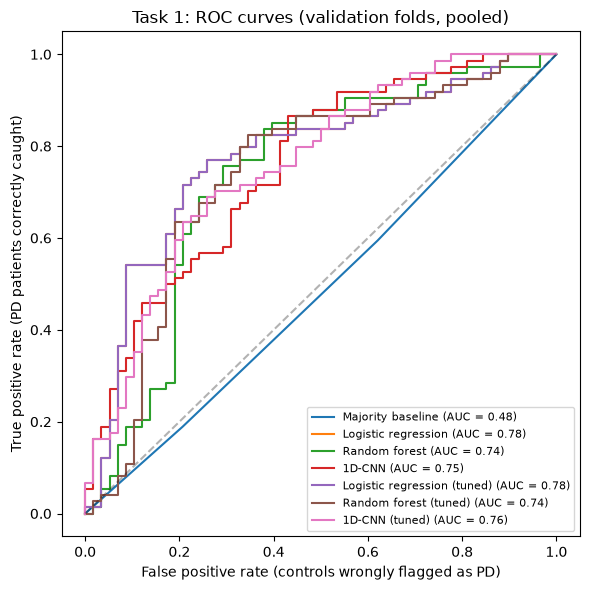

In [ ]:
# visual representation of results for task 1 (roc curves)
fig, ax = plt.subplots(figsize=(6, 6))
for model_name, df in task1_predictions.items():
    fpr, tpr, _ = roc_curve(df.y_true, df.y_prob)
    ax.plot(fpr, tpr, label=f"{model_name} (AUC = {roc_auc_score(df.y_true, df.y_prob):.2f})")
ax.plot([0, 1], [0, 1], "k--", alpha=0.3)
ax.set_xlabel("False positive rate (controls wrongly flagged as PD)")
ax.set_ylabel("True positive rate (PD patients correctly caught)")
ax.set_title("Task 1: ROC curves (validation folds, pooled)")
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "task1_roc_curves.png", dpi=150)
plt.show()

In [ ]:
# since logreg is the best model, elaborate on the metrics specific to it
log_reg = task1_predictions['Logistic regression']
cm = confusion_matrix(log_reg.y_true, log_reg.y_pred)
tn, fp, fn, tp = cm[0, 0], cm[0, 1], cm[1, 0], cm[1, 1]
tpr = tp / (tp+fn)
fpr = fp / (fp+tn)
print(round(tpr, 3))
print(round(fpr, 3))
# decent values, however 1/4 patients still missed

0.757
0.259


,Model,Accuracy change (%),F1 change (%),ROC-AUC change (%)
1,Logistic regression,33.8,7.5,60.2
4,Logistic regression (tuned),33.8,7.5,60.2
6,1D-CNN (tuned),21.6,0.2,56.6
3,1D-CNN,21.6,-0.9,55.8
5,Random forest (tuned),31.1,6.9,52.8
2,Random forest,29.7,4.9,52.0
0,Majority baseline,0.0,0.0,0.0


Not shown in chart (identical to default): ['Logistic regression (tuned)']


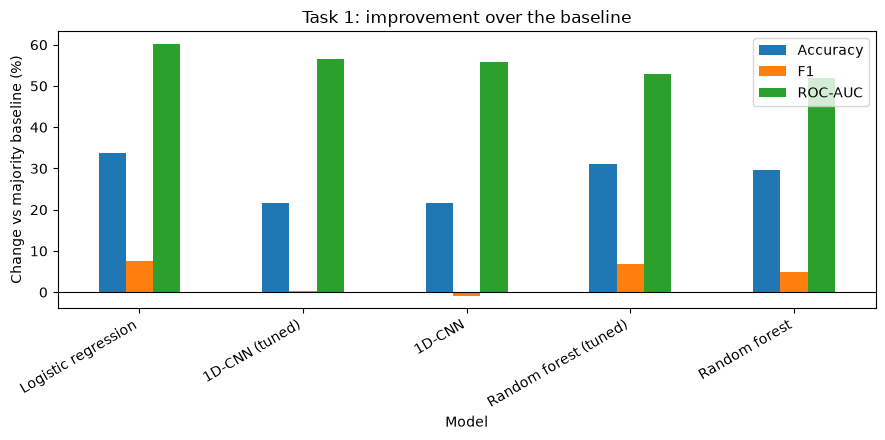

In [27]:
def compare_to_baseline(summary, baseline, metrics, higher_is_better=True):
    base = summary.loc[summary["Model"] == baseline, metrics].iloc[0]
    out = summary[["Model"]].copy()
    for m in metrics:
        diff = summary[m] - base[m]
        if not higher_is_better:
            diff = -diff                      # for error metrics, lower is better
        out[f"{m} change (%)"] = diff / base[m] * 100
    return out

metrics = ["Accuracy", "F1", "ROC-AUC"]
task1_vs_baseline = compare_to_baseline(task1_summary, "Majority baseline", metrics)
display(task1_vs_baseline.round(1))
task1_vs_baseline.round(2).to_csv(RESULTS_DIR / "task1_vs_baseline.csv", index=False)

# chart: skip tuned models that score the same as their default version
scores = task1_summary.set_index("Model")[metrics].astype(float)

def same_as_default(name):
    if not name.endswith(" (tuned)"):
        return False
    default = name.replace(" (tuned)", "")
    return default in scores.index and np.allclose(scores.loc[name], scores.loc[default], atol=1e-4)

omitted = [m for m in scores.index if same_as_default(m)]
keep = [m for m in task1_vs_baseline["Model"] if m != "Majority baseline" and m not in omitted]
if omitted:
    print("Not shown in chart (identical to default):", omitted)

plot_df = task1_vs_baseline.set_index("Model").loc[keep]
plot_df.columns = [c.replace(" change (%)", "") for c in plot_df.columns]
ax = plot_df.plot(kind="bar", figsize=(9, 4.5))
ax.axhline(0, color="black", linewidth=0.8)
ax.set_ylabel("Change vs majority baseline (%)")
ax.set_title("Task 1: improvement over the baseline")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "task1_vs_baseline.png", dpi=150)
plt.show()

## Task 2 results

Comparison and evaluation of the classical models (multiple linear regression, random forests) and the deep learning model (1D-CNN) against the mean baseline. 

In [58]:
def load_predictions(folder, prefix, n_folds=5):
    paths = [folder / f"{prefix}_val_fold{k}.csv"
        for k in range(1, n_folds + 1)]
    return pd.concat([pd.read_csv(path) for path in paths], ignore_index=True)

def regression_metrics(df, target):
    actual = df[f"actual_{target}"]
    predicted = df[f"predicted_{target}"]
    return {
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted))
    }

#### UPDRSM Results

In [59]:
# load predictions for every model
updrsm_models = {
    "Mean baseline": "mean_baseline",
    "MLR": "linear_regression",
    "Random forest": "random_forest",
    "1D-CNN": "cnn",
    "Random forest (tuned)": "random_forest_tuned",
    "1D-CNN (tuned)": "cnn_tuned"
}

updrsm_predictions = {}

for name, prefix in updrsm_models.items():
    df = load_predictions(TASK2_DIR, prefix)
    updrsm_predictions[name] = df

print("UPDRSM models loaded:", list(updrsm_predictions))


UPDRSM models loaded: ['Mean baseline', 'MLR', 'Random forest', '1D-CNN', 'Random forest (tuned)', '1D-CNN (tuned)']


In [60]:
# calculate MAE and RMSE for each model
updrsm_results = []
for name, df in updrsm_predictions.items():
    scores = regression_metrics(df, "UPDRSM")
    updrsm_results.append({
        "Model": name,
        "N": len(df),
        **scores
    })
updrsm_summary = pd.DataFrame(updrsm_results)

# calculate relative performance to baseline 
baseline = updrsm_summary.loc[
    updrsm_summary["Model"] == "Mean baseline"
].iloc[0]

for metric in ["MAE", "RMSE"]:

    updrsm_summary[f"{metric} improvement (%)"] = (
        (baseline[metric] - updrsm_summary[metric])
        / baseline[metric] * 100
    )

updrsm_summary = updrsm_summary.sort_values("RMSE")

display(updrsm_summary.round(3))

updrsm_summary.to_csv(
    RESULTS_DIR / "updrsm_summary.csv",
    index=False
)

,Model,N,MAE,RMSE,MAE improvement (%),RMSE improvement (%)
0,Mean baseline,72,6.503,8.050,0.000,0.000
1,MLR,72,6.506,8.173,-0.047,-1.535
4,Random forest (tuned),72,6.423,8.197,1.226,-1.830
2,Random forest,72,6.609,8.393,-1.638,-4.257
3,1D-CNN,72,7.053,8.632,-8.466,-7.226
5,1D-CNN (tuned),72,7.143,8.772,-9.846,-8.974


In [61]:
# fold by fold performance 
fold_results = []
for name, df in updrsm_predictions.items():
    for fold, part in df.groupby("fold"):
        scores = regression_metrics(part, "UPDRSM")
        fold_results.append({
            "Model": name,
            "Fold": fold,
            **scores
        })

updrsm_folds = pd.DataFrame(fold_results)

display(updrsm_folds.round(3))

# mean and standard deviation of fold errors
fold_summary = (
    updrsm_folds.groupby("Model")[["MAE", "RMSE"]]
    .agg(["mean", "std"])
)

display(fold_summary.round(3))

,Model,Fold,MAE,RMSE
0,Mean baseline,1,6.260,7.222
1,Mean baseline,2,5.340,6.560
2,Mean baseline,3,7.022,8.333
3,Mean baseline,4,8.214,10.198
4,Mean baseline,5,5.778,7.605
5,MLR,1,6.425,7.506
6,MLR,2,5.359,6.918
7,MLR,3,6.802,8.055
8,MLR,4,7.799,9.892
9,MLR,5,6.232,8.318


MAE          RMSE       
                        mean    std   mean    std
Model                                            
1D-CNN                 7.075  1.279  8.539  1.613
1D-CNN (tuned)         7.166  1.413  8.671  1.695
MLR                    6.523  0.888  8.138  1.118
Mean baseline          6.523  1.133  7.984  1.394
Random forest          6.638  1.364  8.327  1.469
Random forest (tuned)  6.445  1.251  8.123  1.472

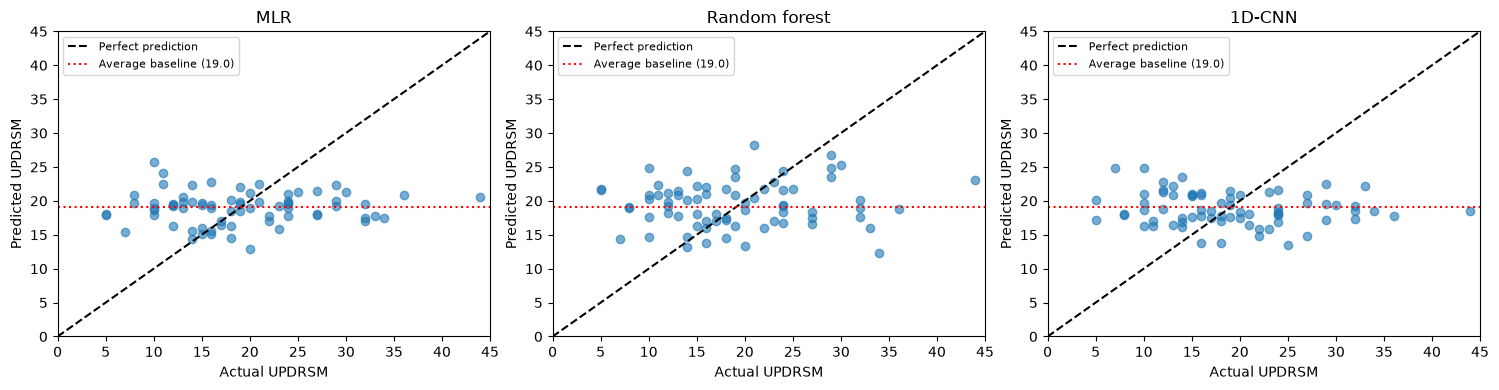

In [ ]:
# model plots
models_to_plot = [
    "MLR",
    "Random forest",
    "1D-CNN"
]

# compare to baseline 
baseline_mean = updrsm_predictions["Mean baseline"]["predicted_UPDRSM"].mean()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, name in zip(axes, models_to_plot):
    df = updrsm_predictions[name]
    ax.scatter(
        df["actual_UPDRSM"],
        df["predicted_UPDRSM"],
        alpha=0.6
    )
    
    # 45 degree line indicates perfect prediction 
    ax.plot([0, 45], [0, 45], "k--", label="Perfect prediction")

    # horizontal reference is the average CV baseline
    ax.axhline(
        baseline_mean,
        color="red",
        linestyle=":",
        label=f"Average baseline ({baseline_mean:.1f})"
    )

    ax.set(
        title=name,
        xlabel="Actual UPDRSM",
        ylabel="Predicted UPDRSM",
        xlim=(0, 45),
        ylim=(0, 45)
    )

    ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig(RESULTS_DIR / "updrsm_predictions.png", dpi=200)
plt.show()

In [69]:
# compare by severity 
severity_results = []

for name, df in updrsm_predictions.items():
    df = df.copy()
    
    # split by ranges
    df["Severity"] = pd.cut(
        df["actual_UPDRSM"],
        bins=[-np.inf, 15, 25, np.inf],
        labels=["Lower", "Middle", "Higher"]
    )

    df["Error"] = (
        df["actual_UPDRSM"] - df["predicted_UPDRSM"]
    )

    for severity, part in df.groupby(
        "Severity", observed=True
    ):

        severity_results.append({
            "Model": name,
            "Severity": severity,
            "N": len(part),
            "MAE": part["Error"].abs().mean(),
            "Mean signed error": part["Error"].mean()
        })

updrsm_severity = pd.DataFrame(severity_results)

display(updrsm_severity.round(2))

,Model,Severity,N,MAE,Mean signed error
0,Mean baseline,Lower,27,7.75,-7.75
1,Mean baseline,Middle,31,2.68,1.10
2,Mean baseline,Higher,14,12.56,12.56
3,MLR,Lower,27,7.69,-7.69
4,MLR,Middle,31,2.93,1.45
5,MLR,Higher,14,12.14,12.14
6,Random forest,Lower,27,8.10,-8.04
7,Random forest,Middle,31,3.09,0.72
8,Random forest,Higher,14,11.52,11.52
9,1D-CNN,Lower,27,8.24,-8.24


#### HoehnYahr results

In [71]:
# load predictions
hy_models = {
    "Mean baseline": "mean_baseline_HoehnYahr",
    "MLR": "linear_regression_HoehnYahr",
    "Random forest": "random_forest_HoehnYahr",
    "1D-CNN": "cnn_HoehnYahr"
}

hy_predictions = {}

for name, prefix in hy_models.items():
    df = load_predictions(TASK2_DIR, prefix)
    hy_predictions[name] = df


In [ ]:
# calculate hy regression performance.
hy_results = []

for name, df in hy_predictions.items():
    scores = regression_metrics(df, "HoehnYahr")
    hy_results.append({
        "Model": name,
        "N": len(df),
        **scores
    })

    hy_summary = pd.DataFrame(hy_results)
    baseline = hy_summary.loc[
        hy_summary["Model"] == "Mean baseline"
    ].iloc[0]
    for metric in ["MAE", "RMSE"]:

        hy_summary[f"{metric} improvement (%)"] = (
            (baseline[metric] - hy_summary[metric])
            / baseline[metric] * 100
        )

    hy_summary = hy_summary.sort_values("RMSE")
display(hy_summary.round(3))
hy_summary.to_csv(
    RESULTS_DIR / "hoehnyahr_summary.csv",
    index=False)

,Model,N,MAE,RMSE,MAE improvement (%),RMSE improvement (%)
1,MLR,72,0.237,0.295,21.297,12.517
2,Random forest,72,0.244,0.302,18.878,10.342
0,Mean baseline,72,0.301,0.337,0.000,0.000
3,1D-CNN,72,0.351,0.427,-16.467,-26.668


#### Comparison between metrics

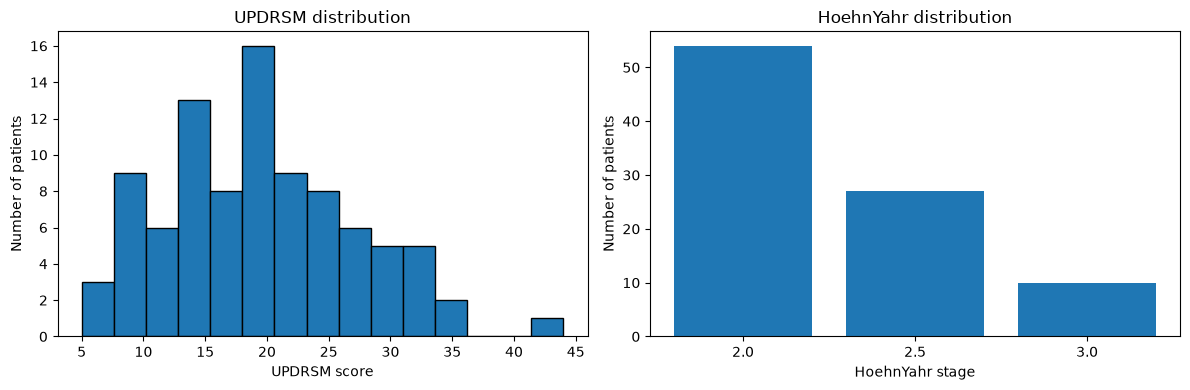

In [ ]:
from src.data import load_metadata
metadata = load_metadata()

severity_data = metadata.loc[
    metadata["Group"].eq("Pt"),
    ["ID", "UPDRSM", "HoehnYahr"]
].dropna().copy()

severity_data = severity_data.rename(
    columns={"ID": "subject"}
)

# plot distributions of each metric 
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(severity_data["UPDRSM"], bins=15, edgecolor="black")
axes[0].set(title="UPDRSM distribution", xlabel="UPDRSM score", ylabel="Number of patients")

stage_counts = (severity_data["HoehnYahr"].value_counts().sort_index())

axes[1].bar(stage_counts.index.astype(str), stage_counts.values)
axes[1].set(
    title="HoehnYahr distribution",
    xlabel="HoehnYahr stage",
    ylabel="Number of patients"
)

plt.tight_layout()
plt.savefig(RESULTS_DIR / "severity_distributions.png", dpi=200)
plt.show()

In [75]:
# investigate prediction errors at each stage
hy_error_results = []
for name, df in hy_predictions.items():
    df = df.copy()

    df["Error"] = (
        df["actual_HoehnYahr"]
        - df["predicted_HoehnYahr"]
    )
    for stage, part in df.groupby("actual_HoehnYahr"):
        hy_error_results.append({
            "Model": name,
            "Actual stage": stage,
            "N": len(part),
            "MAE": part["Error"].abs().mean(),
            "Mean signed error": part["Error"].mean()
        })
hy_errors = pd.DataFrame(hy_error_results)
display(hy_errors.round(3))

,Model,Actual stage,N,MAE,Mean signed error
0,Mean baseline,2.0,42,0.258,-0.258
1,Mean baseline,2.5,23,0.241,0.241
2,Mean baseline,3.0,7,0.758,0.758
3,MLR,2.0,42,0.203,-0.201
4,MLR,2.5,23,0.225,0.220
5,MLR,3.0,7,0.482,0.482
6,Random forest,2.0,42,0.210,-0.210
7,Random forest,2.5,23,0.202,0.199
8,Random forest,3.0,7,0.592,0.592
9,1D-CNN,2.0,42,0.312,-0.295


In [68]:
# final comparison
comparison = pd.concat([
    updrsm_summary.assign(Target="UPDRSM"),
    hy_summary.assign(Target="HoehnYahr")
], ignore_index=True)

# Show the same columns for both outcomes.
comparison = comparison[[
    "Target",
    "Model",
    "N",
    "MAE",
    "RMSE",
    "MAE improvement (%)",
    "RMSE improvement (%)"
]]

display(comparison.round(3))

comparison.to_csv(
    RESULTS_DIR / "severity_target_comparison.csv",
    index=False
)

,Target,Model,N,MAE,RMSE,MAE improvement (%),RMSE improvement (%)
0,UPDRSM,Mean baseline,72,6.503,8.050,0.000,0.000
1,UPDRSM,MLR,72,6.506,8.173,-0.047,-1.535
2,UPDRSM,Random forest (tuned),72,6.423,8.197,1.226,-1.830
3,UPDRSM,Random forest,72,6.609,8.393,-1.638,-4.257
4,UPDRSM,1D-CNN,72,7.053,8.632,-8.466,-7.226
5,UPDRSM,1D-CNN (tuned),72,7.143,8.772,-9.846,-8.974
6,HoehnYahr,MLR,72,0.237,0.295,21.297,12.517
7,HoehnYahr,Random forest,72,0.244,0.302,18.878,10.342
8,HoehnYahr,Mean baseline,72,0.301,0.337,0.000,0.000
9,HoehnYahr,1D-CNN,72,0.351,0.427,-16.467,-26.668
